In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ================= 配置 =================
# 替换为你的真实数据路径
FILE_QPSK = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"
FILE_QPSK2 = "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq"

# 还可以加个 8PSK 对比一下，如果手头有的话
# FILE_8PSK = "..." 

SAMPLES_TO_READ = 100000 # 读多一点，统计特性才准

def read_file(path):
    if path.endswith('.dat'):
        raw = np.fromfile(path, dtype='>i2') # Big Endian int16
        if len(raw) > 1024: raw = raw[1024:] # 跳过头
    else:
        raw = np.fromfile(path, dtype=np.int16)
        
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数并归一化
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    # 去直流
    iq = iq - np.mean(iq)
    # 归一化功率到 1
    iq = iq / np.sqrt(np.mean(np.abs(iq)**2))
    return iq[:SAMPLES_TO_READ]

def calc_cumulants(iq):
    # 计算各阶矩 (Moments)
    m20 = np.mean(iq**2)
    m21 = np.mean(np.abs(iq)**2)
    m40 = np.mean(iq**4)
    m41 = np.mean((iq**3) * np.conj(iq))
    m42 = np.mean((iq**2) * (np.conj(iq)**2))
    
    # 计算累积量 (Cumulants)
    c20 = m20
    c21 = m21
    c40 = m40 - 3 * m20**2
    c42 = m42 - np.abs(m20)**2 - 2 * m21**2
    
    return {
        "|C20|": np.abs(c20),
        "|C21|": np.abs(c21),
        "|C40|": np.abs(c40), # 重点关注这个！
        "|C42|": np.abs(c42)  # 重点关注这个！
    }

# ================= 主程序 =================
print("Reading files...")
try:
    qpsk_data = read_file(FILE_QPSK)
    qpsk2_data = read_file(FILE_QPSK2)
    
    print(f"QPSK samples: {len(qpsk_data)}")
    print(f"QPSK2 samples: {len(qpsk2_data)}")
    
    print("\nCalculating HOC (Higher-Order Cumulants)...")
    
    hoc_qpsk = calc_cumulants(qpsk_data)
    hoc_oqpsk = calc_cumulants(qpsk2_data)
    
    print("-" * 40)
    print(f"{'Feature':<10} | {'QPSK':<10} | {'QPSK2':<10} | {'Diff':<10}")
    print("-" * 40)
    
    for key in hoc_qpsk:
        val1 = hoc_qpsk[key]
        val2 = hoc_oqpsk[key]
        diff = abs(val1 - val2)
        print(f"{key:<10} | {val1:.4f}     | {val2:.4f}     | {diff:.4f}")
        
    print("-" * 40)
    
    # 简单的判决逻辑验证
    # 理论上 QPSK 的 |C40| 很大 (接近1)，OQPSK/8PSK 的 |C40| 很小 (接近0)
    # 理论上 QPSK 的 |C42| 很大 (接近1)，8PSK/OQPSK 的 |C42| 也很小
    
    print("\n[理论预期]")
    print("QPSK:  |C40| ≈ 1.0, |C42| ≈ 1.0")
    print("QPKS2: |C40| ≈ 0.0, |C42| ≈ 1.0 (或更低)")
    print("8PSK:  |C40| ≈ 0.0, |C42| ≈ 0.0")
    
except Exception as e:
    print(f"Error: {e}")

Reading files...
QPSK samples: 100000
QPSK2 samples: 100000

Calculating HOC (Higher-Order Cumulants)...
----------------------------------------
Feature    | QPSK       | QPSK2      | Diff      
----------------------------------------
|C20|      | 0.0586     | 0.0038     | 0.0547
|C21|      | 0.9948     | 1.0019     | 0.0070
|C40|      | 0.0375     | 0.8525     | 0.8149
|C42|      | 0.7810     | 0.8029     | 0.0220
----------------------------------------

[理论预期]
QPSK:  |C40| ≈ 1.0, |C42| ≈ 1.0
QPKS2: |C40| ≈ 0.0, |C42| ≈ 1.0 (或更低)
8PSK:  |C40| ≈ 0.0, |C42| ≈ 0.0


In [5]:
def correct_and_recalc(iq_data):
    # 1. 粗略频偏估计 (基于4次方谱)
    # QPSK 的 4次方会将能量集中到 4*delta_f 处
    fft_len = 4096
    if len(iq_data) > fft_len:
        slice_data = iq_data[:fft_len]
    else:
        slice_data = iq_data
        
    # x^4
    sig_pow4 = slice_data ** 4
    spectrum = np.fft.fft(sig_pow4)
    freqs = np.fft.fftfreq(len(spectrum), 1.0) # 归一化频率
    
    # 找峰值
    peak_idx = np.argmax(np.abs(spectrum))
    est_freq_norm = freqs[peak_idx] / 4.0 # 真实的归一化频偏
    
    print(f"Estimated Normalized Freq Offset: {est_freq_norm:.6f}")
    
    # 2. 校正
    t = np.arange(len(iq_data))
    correction = np.exp(-1j * 2 * np.pi * est_freq_norm * t)
    corrected_iq = iq_data * correction
    
    # 3. 重新计算 HOC
    hoc = calc_cumulants(corrected_iq) # 使用上一段代码里的函数
    print(f"Corrected |C40|: {hoc['|C40|']:.4f}")
    return corrected_iq

# --- 运行验证 ---
print("\n=== Fixing Bad QPSK ===")
# qpsk_data 是那个 0.0375 的坏数据
correct_and_recalc(qpsk_data)


=== Fixing Bad QPSK ===
Estimated Normalized Freq Offset: 0.010315
Corrected |C40|: 0.0282


array([-0.89558583+0.62871397j, -1.23000425+0.65627626j,
       -1.25177113+0.63541543j, ...,  0.08468843+1.21461599j,
       -0.04777696+1.17114292j, -0.08865818+0.99860086j])

Freq Offset Corrected: 0.010284

Scanning SPS...
Step  | Max |C40|  | Best Offset
------------------------------
1     | 0.0035     | 0
2     | 0.0036     | 0
3     | 0.0036     | 0
4     | 0.0066     | 3
5     | 0.0037     | 1
6     | 0.0037     | 0
7     | 0.0054     | 3
8     | 0.0066     | 3
9     | 0.0038     | 0
10    | 0.0037     | 6
11    | 0.0040     | 4
12    | 0.0068     | 3
13    | 0.0049     | 12
14    | 0.0071     | 10
15    | 0.0046     | 6
16    | 0.0067     | 11


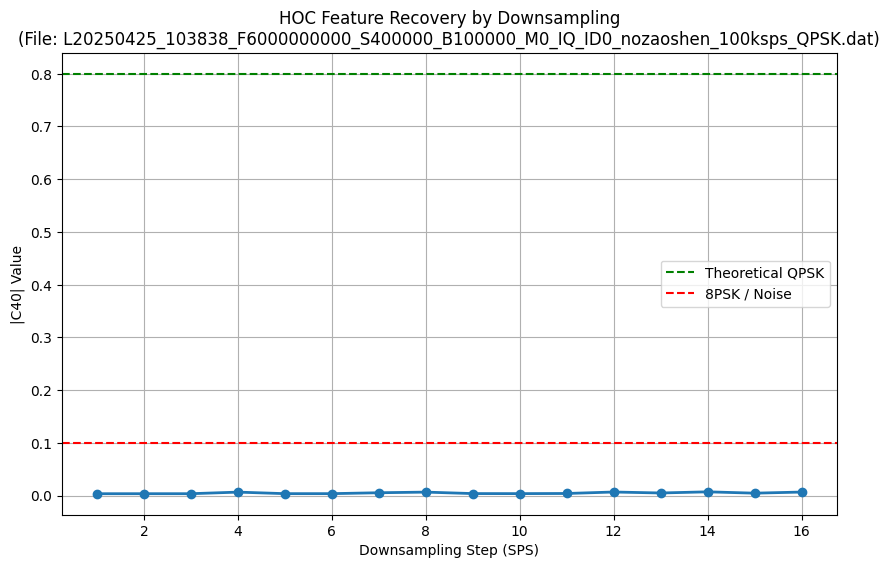

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 你的坏 QPSK 文件路径
FILE_BAD_QPSK = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"

def scan_sps_and_fix(file_path):
    # 1. 读取数据 (大端序)
    raw = np.fromfile(file_path, dtype='>i2')
    if len(raw) > 1024: raw = raw[1024:] # 跳过头
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数 & 归一化
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    iq = iq - np.mean(iq)
    iq = iq / np.sqrt(np.mean(np.abs(iq)**2))
    
    # 2. 频偏校正 (先校正，再抽取)
    # 使用 slice 来加速 FFT
    fft_len = min(len(iq), 8192)
    sig_pow4 = iq[:fft_len] ** 4
    spectrum = np.fft.fft(sig_pow4)
    peak_idx = np.argmax(np.abs(spectrum))
    est_freq_norm = np.fft.fftfreq(len(spectrum), 1.0)[peak_idx] / 4.0
    
    t = np.arange(len(iq))
    correction = np.exp(-1j * 2 * np.pi * est_freq_norm * t)
    iq_corrected = iq * correction
    
    print(f"Freq Offset Corrected: {est_freq_norm:.6f}")

    # 3. 扫描 SPS (1 到 16)
    results = []
    print("\nScanning SPS...")
    print(f"{'Step':<5} | {'Max |C40|':<10} | {'Best Offset'}")
    print("-" * 30)
    
    for step in range(1, 17):
        # 对于每个步长，我们需要尝试所有可能的起始点 (offset)
        # 找到最佳的采样时刻 (最佳眼图张开点)
        max_c40_for_step = 0
        best_offset = 0
        
        for offset in range(step):
            sub_sig = iq_corrected[offset::step]
            if len(sub_sig) < 100: continue
            
            # 计算 C40
            m20 = np.mean(sub_sig**2)
            m40 = np.mean(sub_sig**4)
            c40 = m40 - 3 * m20**2
            abs_c40 = np.abs(c40)
            
            if abs_c40 > max_c40_for_step:
                max_c40_for_step = abs_c40
                best_offset = offset
        
        results.append(max_c40_for_step)
        
        # 打印高亮显示 > 0.6 的结果
        mark = " <--- FOUND IT!" if max_c40_for_step > 0.6 else ""
        print(f"{step:<5} | {max_c40_for_step:.4f}     | {best_offset}{mark}")

    # 4. 绘图
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, 17), results, 'o-', linewidth=2)
    plt.axhline(y=0.8, color='g', linestyle='--', label='Theoretical QPSK')
    plt.axhline(y=0.1, color='r', linestyle='--', label='8PSK / Noise')
    plt.title(f"HOC Feature Recovery by Downsampling\n(File: {file_path.split('/')[-1]})")
    plt.xlabel("Downsampling Step (SPS)")
    plt.ylabel("|C40| Value")
    plt.grid(True)
    plt.legend()
    plt.show()

# 运行
scan_sps_and_fix(FILE_BAD_QPSK)

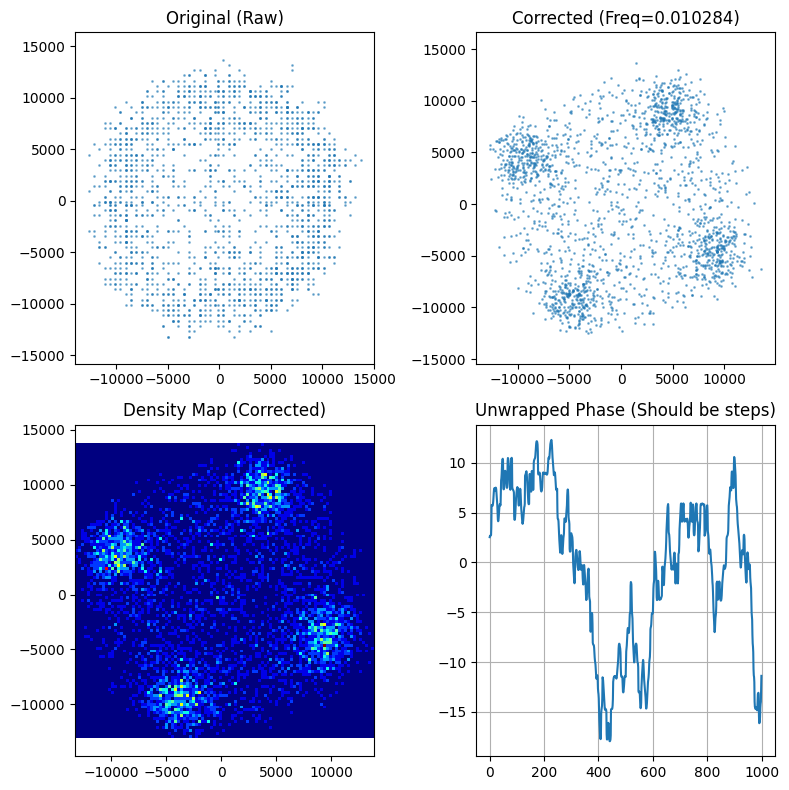

In [7]:
import numpy as np
import matplotlib.pyplot as plt

FILE_BAD_QPSK = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"

def plot_constellation(file_path):
    # 1. 读取
    raw = np.fromfile(file_path, dtype='>i2')
    if len(raw) > 1024: raw = raw[1024:]
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    iq = iq - np.mean(iq)
    
    # 2. 应用之前的粗略频偏 (0.010284)
    # 如果这个值不准，星座图依然会转圈
    est_freq_norm = 0.010284 
    t = np.arange(len(iq))
    correction = np.exp(-1j * 2 * np.pi * est_freq_norm * t)
    iq_corrected = iq * correction
    
    # 3. 绘图 (只画前 5000 个点，防止点太多糊在一起)
    plt.figure(figsize=(8, 8))
    
    # 原始数据 (转圈的)
    plt.subplot(2, 2, 1)
    plt.scatter(iq.real[:2000], iq.imag[:2000], s=1, alpha=0.5)
    plt.title("Original (Raw)")
    plt.axis('equal')
    
    # 校正后 (希望能停下来)
    plt.subplot(2, 2, 2)
    plt.scatter(iq_corrected.real[:2000], iq_corrected.imag[:2000], s=1, alpha=0.5)
    plt.title(f"Corrected (Freq={est_freq_norm})")
    plt.axis('equal')
    
    # 放大看细节 (如果有聚类的话)
    plt.subplot(2, 2, 3)
    plt.hist2d(iq_corrected.real[:5000], iq_corrected.imag[:5000], bins=100, cmap='jet')
    plt.title("Density Map (Corrected)")
    plt.axis('equal')
    
    # 相位随时间变化 (检查是否还有残余斜率)
    plt.subplot(2, 2, 4)
    phase = np.unwrap(np.angle(iq_corrected[:1000]))
    plt.plot(phase)
    plt.title("Unwrapped Phase (Should be steps)")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

plot_constellation(FILE_BAD_QPSK)

d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat...
Applying blind frequency correction...
Estimated Freq Offset (Torch): 0.010315


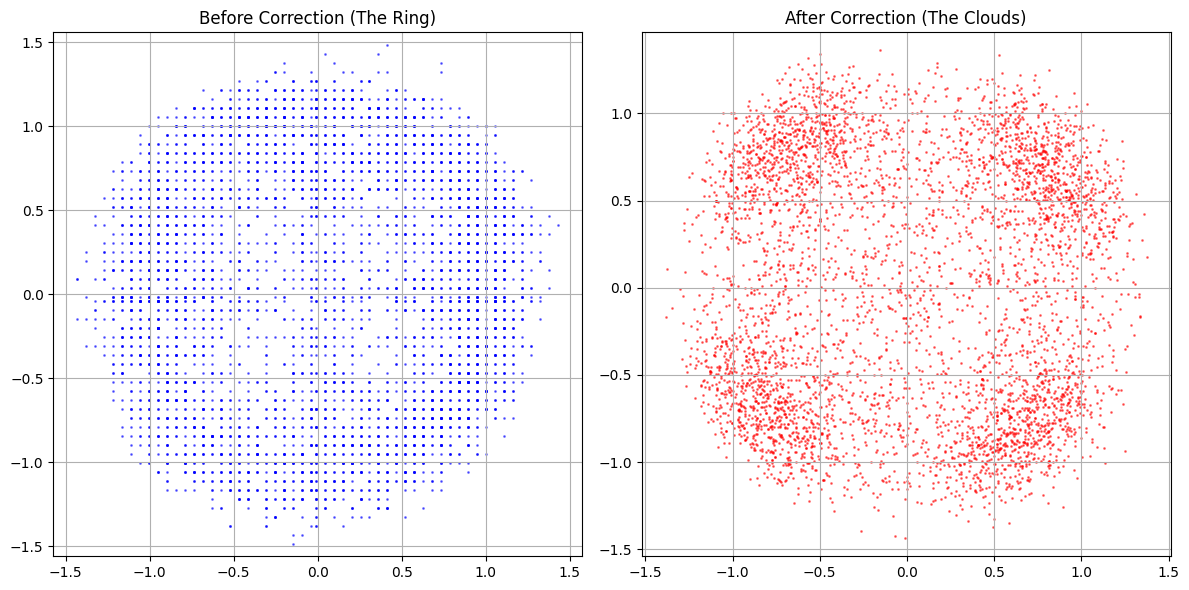

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 你的坏 QPSK 文件路径
FILE_BAD_QPSK = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"

# 模拟 PyTorch 环境下的校正函数
def correct_freq_offset_blind_torch(iq_data_torch):
    """
    完全复刻将要加入数据生成器的 PyTorch 版本校正逻辑
    """
    # 确保是 1D Tensor
    if iq_data_torch.dim() > 1:
        iq_data_torch = iq_data_torch.squeeze()
        
    n = len(iq_data_torch)
    # 为了速度和鲁棒性，取前 4096 点估算 (足够了)
    fft_n = min(n, 4096)
    x = iq_data_torch[:fft_n]
    
    # x^4 频谱分析
    # 注意：这里不仅要找到峰值，还要处理频谱搬移
    spectrum = torch.fft.fft(x**4)
    
    # 找到峰值索引
    peak_idx = torch.argmax(torch.abs(spectrum)).item()
    
    # 转换为归一化频率 (-0.5 到 0.5)
    if peak_idx > fft_n // 2:
        peak_idx -= fft_n
        
    est_freq = peak_idx / float(fft_n) / 4.0
    
    print(f"Estimated Freq Offset (Torch): {est_freq:.6f}")
    
    # 生成校正向量
    t = torch.arange(n, device=iq_data_torch.device)
    # 负号用于反向旋转
    correction = torch.exp(-1j * 2 * np.pi * est_freq * t)
    
    return iq_data_torch * correction

def test_correction():
    print(f"Loading {FILE_BAD_QPSK}...")
    
    # 1. 读取数据 (模拟真实环境)
    raw = np.fromfile(FILE_BAD_QPSK, dtype='>i2') # Big Endian
    if len(raw) > 1024: raw = raw[1024:]
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数
    iq_np = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    # 归一化 (模拟 generate_tensor_data 的输入)
    iq_np = iq_np - np.mean(iq_np)
    iq_np = iq_np / np.sqrt(np.mean(np.abs(iq_np)**2))
    
    # 转 Tensor
    iq_tensor = torch.from_numpy(iq_np)
    
    # 2. 执行校正
    print("Applying blind frequency correction...")
    iq_corrected = correct_freq_offset_blind_torch(iq_tensor)
    
    # 转回 Numpy 绘图
    iq_corr_np = iq_corrected.numpy()
    
    # 3. 绘图对比
    plt.figure(figsize=(12, 6))
    
    # 原始信号 (前 5000 点)
    plt.subplot(1, 2, 1)
    plt.scatter(iq_np.real[:5000], iq_np.imag[:5000], s=1, alpha=0.5, c='blue')
    plt.title("Before Correction (The Ring)")
    plt.axis('equal')
    plt.grid(True)
    
    # 校正后信号 (前 5000 点)
    plt.subplot(1, 2, 2)
    plt.scatter(iq_corr_np.real[:5000], iq_corr_np.imag[:5000], s=1, alpha=0.5, c='red')
    plt.title(f"After Correction (The Clouds)")
    plt.axis('equal')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    test_correction()

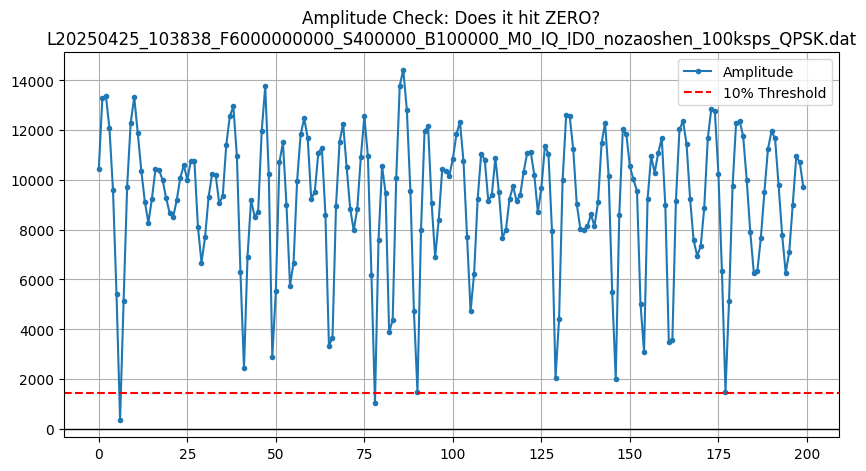

In [9]:
import numpy as np
import matplotlib.pyplot as plt

FILE_BAD_QPSK = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"

def check_zero_crossing(file_path):
    # 读取
    raw = np.fromfile(file_path, dtype='>i2')
    if len(raw) > 1024: raw = raw[1024:]
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    
    # 计算幅度
    amp = np.abs(iq)
    
    # 绘图 (取前 200 个点，看细节)
    plt.figure(figsize=(10, 5))
    plt.plot(amp[:200], '.-', label='Amplitude')
    plt.axhline(y=0, color='k', linewidth=1)
    # 画一条 10% 峰值的线，看看有没有点落在这下面
    peak = np.max(amp[:200])
    plt.axhline(y=peak*0.1, color='r', linestyle='--', label='10% Threshold')
    
    plt.title(f"Amplitude Check: Does it hit ZERO?\n{file_path.split('/')[-1]}")
    plt.grid(True)
    plt.legend()
    plt.show()

check_zero_crossing(FILE_BAD_QPSK)